# Lab 10 - Odometry vs gyro-aided localization

The "54" trajectory (Lab 7), driven twice by the same program, `Lab10_odom_gyro.qrs`, from the same taped start pose. Only the course used for localization and control changes:

- run A (`MODE = 0`): `course = course_odom`, from the encoders
- run B (`MODE = 1`): `course = course + gyro_inc`, from the gyro, with $b_0$ = the mean of 300 samples at rest at the start, and $s = 0.35\%$ (Lab 9)

Controller: my go-to-goal law from Lab 7.

In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import pandas as pd                 # tables
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select files

Saving gyro.txt to gyro.txt
Saving odom_2.txt to odom_2.txt


In [2]:
cols = ['t_ms', 'i', 'theta_l', 'theta_r', 'gz', 'tg', 'x', 'y', 'course']
runA = pd.read_csv('odom_2.txt', names=cols)    # run A: course from the encoders
runB = pd.read_csv('gyro.txt', names=cols)      # run B: course from the gyro

for name, run in [('A', runA), ('B', runB)]:
    run['t'] = (run.t_ms - run.t_ms.iloc[0]) / 1000     # s
    run['seg'] = run.i + 1                              # segment number: the robot drives to waypoint i
    print(f'run {name}: {len(run)} rows, {run.t.iloc[-1]:.1f} s, one row every {run.t_ms.diff().median():.0f} ms')

run A: 293 rows, 38.5 s, one row every 130 ms
run B: 305 rows, 44.2 s, one row every 142 ms


## 1. Ideal trajectory

In [21]:
# Waypoints in cm; point 0 is the start (the robot faces +x)
wp = np.array([[0, 0],
               [50, 0], [50, 50], [0, 50], [0, 100], [50, 100],    # digit 5
               [80, 100],                                          # gap
               [80, 50], [130, 50], [130, 100], [130, 0]])         # digit 4
X_ref, Y_ref = wp[:, 0], wp[:, 1]

course_ref = np.degrees(np.arctan2(np.diff(Y_ref), np.diff(X_ref)))    # deg
path_ref = np.hypot(np.diff(X_ref), np.diff(Y_ref))                    # cm

for k in range(10):
    print(f'segment {k + 1}: course_ref {course_ref[k]:6.1f} deg, path_ref {path_ref[k]:4.0f} cm')
print(f'total path_ref = {path_ref.sum():.0f} cm')

segment 1: course_ref    0.0 deg, path_ref   50 cm
segment 2: course_ref   90.0 deg, path_ref   50 cm
segment 3: course_ref  180.0 deg, path_ref   50 cm
segment 4: course_ref   90.0 deg, path_ref   50 cm
segment 5: course_ref    0.0 deg, path_ref   50 cm
segment 6: course_ref    0.0 deg, path_ref   30 cm
segment 7: course_ref  -90.0 deg, path_ref   50 cm
segment 8: course_ref    0.0 deg, path_ref   50 cm
segment 9: course_ref   90.0 deg, path_ref   50 cm
segment 10: course_ref  -90.0 deg, path_ref  100 cm
total path_ref = 530 cm


10 segments, 530 cm. There is no turn between segments 5 and 6 (one 80-cm line), and the hardest turn is the $180°$ turn before segment 10.

## 2. Trajectories

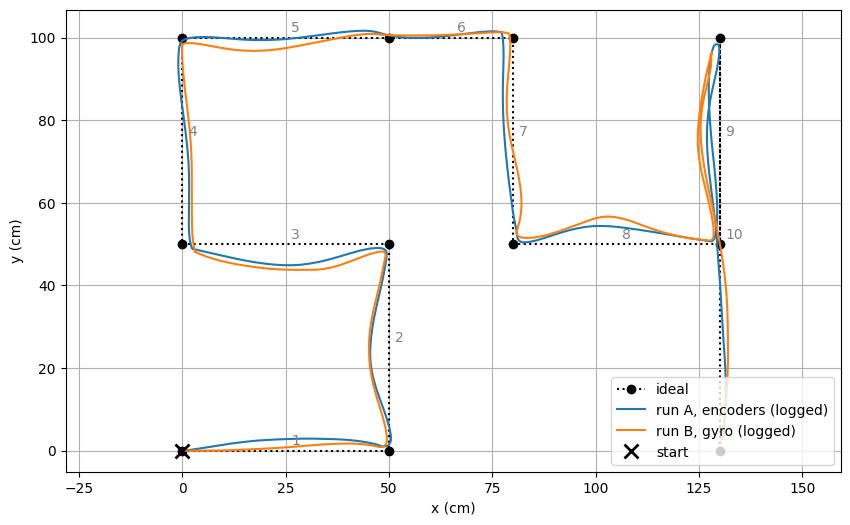

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(X_ref, Y_ref, 'k:o', label='ideal')
plt.plot(runA.x, runA.y, label='run A, encoders (logged)')
plt.plot(runB.x, runB.y, label='run B, gyro (logged)')
plt.plot(0, 0, 'kx', markersize=10, mew=2, label='start')
for k in range(10):                                    # segment numbers at the midpoints
    plt.annotate(str(k + 1), ((X_ref[k] + X_ref[k + 1]) / 2, (Y_ref[k] + Y_ref[k + 1]) / 2),
                 textcoords='offset points', xytext=(4, 4), color='gray')
plt.axis('equal'); plt.grid(True)
plt.xlabel('x (cm)'); plt.ylabel('y (cm)'); plt.legend()
plt.show()

Both logged paths stay within 5-7 cm of the ideal "54" and and end within 4 cm of the last waypoint. This does not show that the localization was good. `x` and `y` are the robot's own estimate, and the controller steers this estimate to the waypoints, so the plot shows how well the controller follows its own estimate.

The deviations from the ideal come from the controller. In the run videos the robot overshoots each turn and then drives along an arc back to the line.

In [5]:
# courseAngle and the distance to the target waypoint
for run in [runA, runB]:
    bearing = np.degrees(np.arctan2(Y_ref[run.i + 1] - run.y, X_ref[run.i + 1] - run.x))
    run['ca'] = (bearing - np.degrees(run.course) + 180) % 360 - 180     # deg, wrapped to [-180, 180)
    run['dist'] = np.hypot(X_ref[run.i + 1] - run.x, Y_ref[run.i + 1] - run.y)   # cm

# overshoot
turns = [2, 3, 4, 5, 7, 8, 9, 10]              # segments that start with a turn
for name, run in [('A', runA), ('B', runB)]:
    over = []
    for k in turns:
        a = run.ca[(run.seg == k) & (run.dist > 10)]
        sign = np.sign(a.iloc[0])                 # + left turn, − right turn
        over.append((-sign * a).max())
    print(f'run {name}: overshoot (deg) after the turn into segment ' +
          ', '.join(f'{k}: {o:.0f}' for k, o in zip(turns, over)))

run A: overshoot (deg) after the turn into segment 2: 24, 3: 22, 4: 3, 5: 5, 7: 5, 8: 22, 9: 13, 10: 14
run B: overshoot (deg) after the turn into segment 2: 22, 3: 27, 4: 4, 5: 14, 7: 7, 8: 30, 9: 20, 10: 16


After the left turns (segments 2, 3, 8, 9) `courseAngle` goes 13-30 deg past zero, after the right turns (4, 5, 7) 3-14 deg, and after the 180° turn (10) 14-16 deg. While the robot steers back, it already drives ($\cos^4$ is still 0.78 at 20°), so it arcs out to the side and back. A likely reason for the overshoot is the slow loop: the controller sees the course only every 135 ms, so a fast turn goes past zero before it can react (a hypothesis). Why the left turns overshoot more than the right ones I did not find out; a difference between the motors is possible. The corners are also cut, because the robot goes on to the next waypoint as soon as its estimate is within 4 cm.

## 3. Offline recomputation

Each log holds both sensors, the wheel angles and the gyro rate, but each run steered with only one of them. Here both courses are computed for both runs, which gives 4 paths: run A with the encoder course and the gyro course, run B with the gyro course and the encoder course. $b_0$ was subtracted on the robot but not logged, so it is recovered first.

In [6]:
r, B = 4.2, 19.4       # wheel radius, track width (cm)
s = 0.0035             # gyro scale factor, from Lab 9
TICKS = 3906           # gyro timestamp ticks per second (as in the program)

def gyro_k(run):
    # gyro_inc = k * (gz - b0) in the program: k for each row (rad per mdeg/s)
    dt = run.tg.diff() / TICKS                     # s
    return dt / 1000 / (1 + s) * np.pi / 180

# b0 was averaged on the robot and only printed. In run B every row adds k * (gz - b0) to the course,
# so each row gives back b0 = gz - (change of course) / k
b0_rows = runB.gz - runB.course.diff() / gyro_k(runB)
b0 = b0_rows.median()
print(f'b0 = {b0:.1f} mdeg/s (spread over the rows: {b0_rows.std():.0e} mdeg/s)')
print(f'run A started {(runB.tg.iloc[0] - runA.tg.iloc[0]) / TICKS:.0f} s before run B; '
      f'its first row (at rest) reads gz = {runA.gz.iloc[0]} mdeg/s')

b0 = 638.2 mdeg/s (spread over the rows: 6e-11 mdeg/s)
run A started 157 s before run B; its first row (at rest) reads gz = 813 mdeg/s


$b_0 = 638.2$ mdeg/s ($0.638$ deg/s), the same in every row, so this is exactly the value the robot subtracted. (If the formula for $k$ were wrong, for example the ticks per second, the rows would give different values, since `gz` changes from row to row).

In [19]:
def recompute(run, b0):
    # both localization methods from the raw sensors of one run
    run['path'] = (run.theta_r + run.theta_l) / 2 * r * np.pi / 180          # cm
    run['c_odom'] = (run.theta_r - run.theta_l) * r / B * np.pi / 180        # encoder course, rad
    run['c_gyro'] = (gyro_k(run) * (run.gz - b0)).fillna(0).cumsum()         # gyro course, rad
    dpath = run.path.diff().fillna(0)                                        # cm per row
    run['x_odom'] = (dpath * np.cos(run.c_odom)).cumsum()                    # cm
    run['y_odom'] = (dpath * np.sin(run.c_odom)).cumsum()
    run['x_gyro'] = (dpath * np.cos(run.c_gyro)).cumsum()
    run['y_gyro'] = (dpath * np.sin(run.c_gyro)).cumsum()

recompute(runA, b0)
recompute(runB, b0)     # run A uses run B's b0 (see above)

# check: run A drove with c_odom, run B with c_gyro
dA = np.hypot(runA.x - runA.x_odom, runA.y - runA.y_odom).max()
dB = np.hypot(runB.x - runB.x_gyro, runB.y - runB.y_gyro).max()
print(f'run A: max distance to the logged x, y {dA:.3f} cm, '
      f'max course difference {np.degrees((runA.course - runA.c_odom).abs().max()):.4f} deg')
print(f'run B: max distance to the logged x, y {dB:.3f} cm, '
      f'max course difference {np.degrees((runB.course - runB.c_gyro).abs().max()):.4f} deg')

run A: max distance to the logged x, y 0.000 cm, max course difference 0.0000 deg
run B: max distance to the logged x, y 0.007 cm, max course difference 0.0025 deg


Both on-robot estimates are reproduced from the raw sensors: run A exactly, and run B to within 0.01 cm and 0.003 deg (the gyro increment of the first row is not known). So the offline code computes what the robot computed, and the other two paths below can be trusted as.


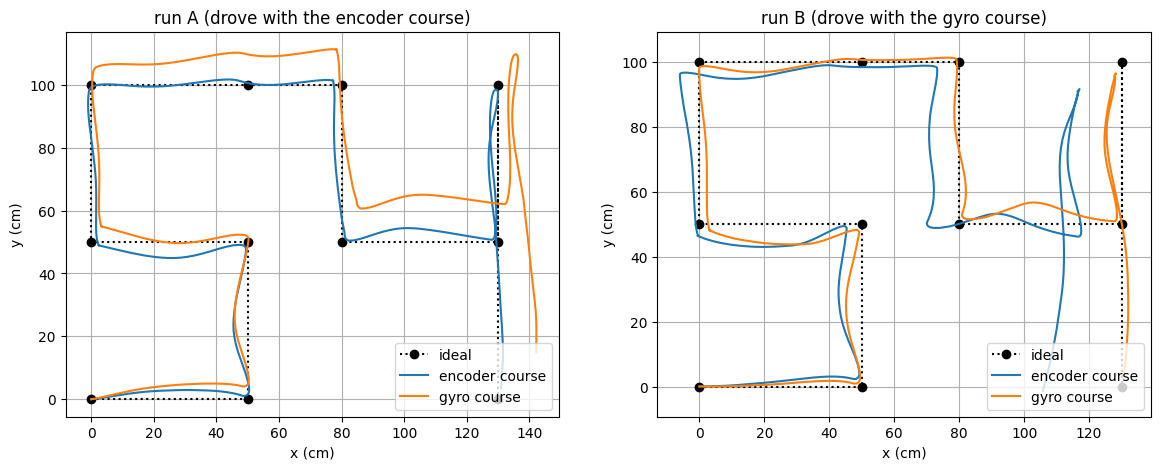

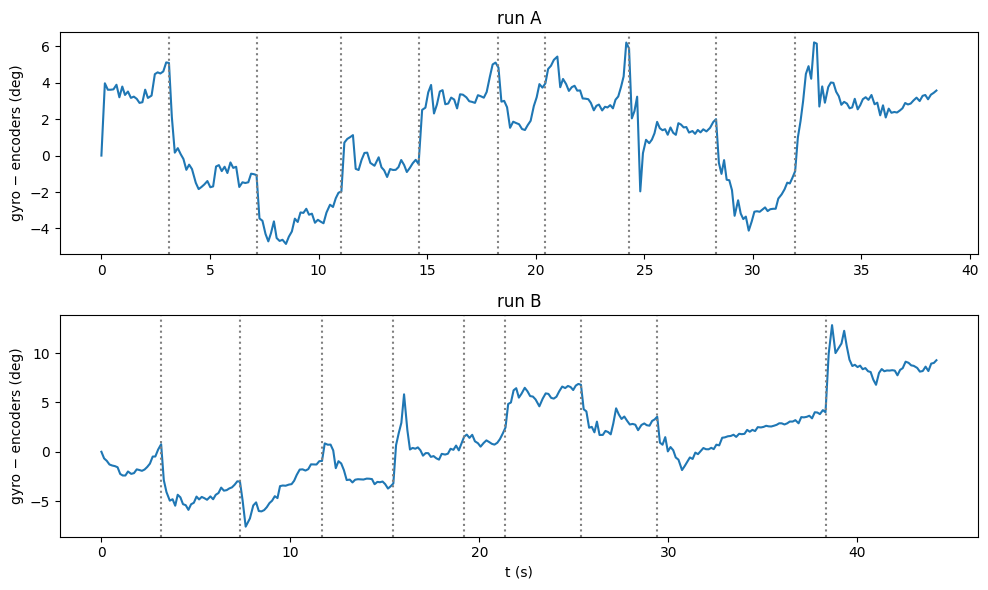

run A: gyro − encoders +3.6 deg at the end, max |.| 6.2 deg; the two end points are 16.0 cm apart
run B: gyro − encoders +9.3 deg at the end, max |.| 12.8 deg; the two end points are 25.2 cm apart


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, run, name in [(ax[0], runA, 'run A (drove with the encoder course)'),
                     (ax[1], runB, 'run B (drove with the gyro course)')]:
    a.plot(X_ref, Y_ref, 'k:o', label='ideal')
    a.plot(run.x_odom, run.y_odom, label='encoder course')
    a.plot(run.x_gyro, run.y_gyro, label='gyro course')
    a.set_title(name); a.axis('equal'); a.grid(True)
    a.set_xlabel('x (cm)'); a.set_ylabel('y (cm)'); a.legend()
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
for a, run, name in [(ax[0], runA, 'run A'), (ax[1], runB, 'run B')]:
    a.plot(run.t, np.degrees(run.c_gyro - run.c_odom))
    for t0 in run.t[run.seg.diff() > 0]:            # a new segment starts: the robot turns
        a.axvline(t0, ls=':', c='gray')
    a.set_title(name); a.set_ylabel('gyro − encoders (deg)')
ax[1].set_xlabel('t (s)')
plt.tight_layout(); plt.show()

for name, run in [('A', runA), ('B', runB)]:
    gap = np.degrees(run.c_gyro - run.c_odom)
    ends = np.hypot(run.x_gyro.iloc[-1] - run.x_odom.iloc[-1], run.y_gyro.iloc[-1] - run.y_odom.iloc[-1])
    print(f'run {name}: gyro − encoders {gap.iloc[-1]:+.1f} deg at the end, max |.| {gap.abs().max():.1f} deg; '
          f'the two end points are {ends:.1f} cm apart')

**Where do the two courses disagree?** The gap is almost flat while the robot drives, and it steps at the dotted lines, where a new segment starts and the robot turns.

In [20]:
from scipy.integrate import cumulative_trapezoid

for run in [runA, runB]:
    w = (run.gz - b0) / 1000 / (1 + s)                                                # deg/s
    run['c_trap'] = np.radians(cumulative_trapezoid(w, run.tg / TICKS, initial=0))    # gyro course, trapezoid rule, rad

turn_ref = np.diff(course_ref, prepend=0)        # the turn at the start of each segment, deg
left, right = [2, 3, 8, 9], [4, 5, 7, 10]        # segments that start with a left / right turn

for name, run in [('A', runA), ('B', runB)]:
    gap_rule = np.degrees(run.c_gyro - run.c_odom).groupby(run.seg).last()    # gap at the end of each segment, deg
    gap_trap = np.degrees(run.c_trap - run.c_odom).groupby(run.seg).last()
    tab = pd.DataFrame({'turn_ref': turn_ref,
                        'robot rule': np.diff(gap_rule, prepend=0),           # change of the gap on each segment
                        'trapezoid': np.diff(gap_trap, prepend=0)}, index=range(1, 11))
    print(f'run {name}: change of gyro − encoders on each segment (deg)')
    print(tab.round(1).T.to_string())
    print(f'gap at the end: {gap_rule.iloc[-1]:+.1f} (robot rule), {gap_trap.iloc[-1]:+.1f} (trapezoid); '
          f'robot rule, left-turn segments {tab.loc[left, "robot rule"].sum():+.1f}, '
          f'right-turn segments {tab.loc[right, "robot rule"].sum():+.1f}\n')

run A: change of gyro − encoders on each segment (deg)
             1     2     3     4     5    6     7     8     9      10
turn_ref    0.0  90.0  90.0 -90.0 -90.0  0.0 -90.0  90.0  90.0 -180.0
robot rule  5.1  -6.1  -1.0   1.8   5.3 -1.4   2.5  -4.4  -3.1    4.8
trapezoid   5.8  -7.6  -0.8   2.6   6.8 -0.6  -0.2  -3.0   0.2    2.1
gap at the end: +3.6 (robot rule), +5.3 (trapezoid); robot rule, left-turn segments -14.6, right-turn segments +14.4

run B: change of gyro − encoders on each segment (deg)
             1     2     3     4     5    6     7     8     9      10
turn_ref    0.0  90.0  90.0 -90.0 -90.0  0.0 -90.0  90.0  90.0 -180.0
robot rule  0.2  -3.2   2.0  -2.5   4.4  1.0   5.0  -3.6   0.9    5.1
trapezoid   1.7  -5.1  -0.5  -1.9   5.4  0.1   4.5  -5.4   1.9    8.1
gap at the end: +9.3 (robot rule), +9.0 (trapezoid); robot rule, left-turn segments -3.8, right-turn segments +11.9



In [10]:
# run B, segment 9: the slow crawl near waypoint 9 (§5): rows within 10 cm of the waypoint where the robot moved 1 cm or less
crawl = runB[(runB.seg == 9) & (runB.dist < 10) & (runB.path.diff() <= 1)]
print(f'run B crawl: {len(crawl)} rows, {crawl.t.iloc[-1] - crawl.t.iloc[0]:.1f} s, '
      f'moved {crawl.path.iloc[-1] - crawl.path.iloc[0]:.1f} cm; '
      f'left wheel {crawl.theta_l.iloc[-1] - crawl.theta_l.iloc[0]} deg, right wheel {crawl.theta_r.iloc[-1] - crawl.theta_r.iloc[0]} deg')
for label, c in [('gyro, robot rule', runB.c_gyro), ('gyro, trapezoid', runB.c_trap), ('encoders', runB.c_odom)]:
    print(f'  course change, {label}: {np.degrees(c.diff()[crawl.index].sum()):+.1f} deg')

run B crawl: 38 rows, 5.3 s, moved 1.4 cm; left wheel 37 deg, right wheel 2 deg
  course change, gyro, robot rule: -5.5 deg
  course change, gyro, trapezoid: -6.4 deg
  course change, encoders: -9.1 deg


Over a segment that starts with a left turn (+90) the gap falls, and over one that starts with a right turn (−90, −180) it rises. With either rule, in 13 (trapezoid) or 14 (robot rule) of the 16 such segments **the encoders count more turning than the gyro**. (Run B's segment 9 also holds the crawl near waypoint 9, during which the gap rose by 3.6 deg; without it, its turn fits the pattern too.) The two rules give the same pattern, but the change on one segment differs between them by up to 3.3 deg (run A, segment 9), so each number is uncertain by about that much. The gap at the end changes less (A +3.6 / +5.3 deg, B +9.3 / +9.0 deg).


In [11]:
for name, run in [('A', runA), ('B', runB)]:
    # B: the least-squares wheel base that makes the encoder course match the gyro
    # (the same formula as the program's "Identification base" block)
    arc = (run.theta_r - run.theta_l).diff() * r * np.pi / 180    # cm, = B * (change of the encoder course)
    B_hat = []
    for c in [run.c_gyro, run.c_trap]:                            # gyro course with the robot rule and the trapezoid rule
        g = c.diff()                                              # change of the gyro course, rad
        B_hat.append((arc * g).sum() / (g * g).sum())
    w = (run.gz - b0) / 1000 / (1 + s)                            # deg/s
    print(f'run {name}: B_hat = {B_hat[0]:.2f} cm (robot rule), {B_hat[1]:.2f} cm (trapezoid), vs {B} cm; '
          f'max |rate| {w.abs().max():.0f} deg/s (range 286.7)')

run A: B_hat = 19.55 cm (robot rule), 19.50 cm (trapezoid), vs 19.4 cm; max |rate| 182 deg/s (range 286.7)
run B: B_hat = 19.50 cm (robot rule), 19.71 cm (trapezoid), vs 19.4 cm; max |rate| 185 deg/s (range 286.7)


- **B:** $\hat B$ = 19.50-19.71 cm, depending on the run and the rule: 0.5-1.6 % above 19.4 cm, so the encoders count ≈ 0.5-1.5 deg too much in a 90° turn. That is less than the up to ≈ 8 deg in a single segment, and a wrong $B$ would give the same share in every turn. So a wrong $B$ explains only a part.
- **Slip:** what is left changes from segment to segment, with the encoders counting more turning than the gyro. The clearest case is run B's crawl: the robot pivoted slowly (≈ 1 deg/s) on almost only the left wheel. The gyro saw −5.5 deg (−6.4 deg with the trapezoid rule), the encoders counted −9.1 deg. The wheels turned more than the robot did, which is wheel slip (Borenstein, Everett & Feng 1996, §5.1: a non-systematic error).
- **Gyro bias:** the value the robot subtracted is known exactly, but a drift of the true bias during the run is not (≈ 1.7 deg over run B if it drifts as in Lab 9). In run A's offline gyro course, $b_0$ is borrowed from run B: ±3.8 deg over the run per 0.1 deg/s.
- **Scale factor:** $s$ is corrected; Lab 9 bounds what is left at $|s| \lesssim 0.65\%$, which is at most 0.6 deg per 90° turn.
- **Saturation:** none. The fastest turns reached 182 deg/s (A) and 185 deg/s (B), below the 286.7 deg/s range.
- **Gyro sampling** (not in the brief's list): the gyro is read only once per row, so a 90° turn gets only 6-9 readings. The two integration rules give the same pattern, but a segment's number can differ by up to 3.3 deg between them. So part of each per-segment number may come from the sampling, not from slip. A faster loop or log (the brief asks for ≈ 10 ms; this loop ran at ≈ 130-140 ms) would separate the two.

## 4. Course per segment

In [12]:
def segment_course(run, course):
    # mean course of each segment while driving (if moved more than 1 cm in the row), deg
    driving = run.path.diff() > 1
    return np.degrees(course[driving].groupby(run.seg[driving]).mean()).values

cA = segment_course(runA, runA.course)      # logged course (run A: encoders)
cB = segment_course(runB, runB.course)      # logged course (run B: gyro)
d_cA, d_cB = cA - course_ref, cB - course_ref

for k in range(10):
    print(f'segment {k + 1}: course_ref {course_ref[k]:6.1f} | A {cA[k]:6.1f} ({d_cA[k]:+5.1f}) | '
          f'B {cB[k]:6.1f} ({d_cB[k]:+5.1f}) deg')
print(f'mean |d_course|: A {np.abs(d_cA).mean():.1f} deg, B {np.abs(d_cB).mean():.1f} deg')

segment 1: course_ref    0.0 | A    1.5 ( +1.5) | B    0.7 ( +0.7) deg
segment 2: course_ref   90.0 | A   90.1 ( +0.1) | B   89.3 ( -0.7) deg
segment 3: course_ref  180.0 | A  178.7 ( -1.3) | B  180.2 ( +0.2) deg
segment 4: course_ref   90.0 | A   93.7 ( +3.7) | B   93.8 ( +3.8) deg
segment 5: course_ref    0.0 | A    6.8 ( +6.8) | B    7.1 ( +7.1) deg
segment 6: course_ref    0.0 | A    0.2 ( +0.2) | B    0.5 ( +0.5) deg
segment 7: course_ref  -90.0 | A  -85.3 ( +4.7) | B  -83.9 ( +6.1) deg
segment 8: course_ref    0.0 | A    0.1 ( +0.1) | B   -3.0 ( -3.0) deg
segment 9: course_ref   90.0 | A   90.4 ( +0.4) | B   90.1 ( +0.1) deg
segment 10: course_ref  -90.0 | A  -89.0 ( +1.0) | B  -89.4 ( +0.6) deg
mean |d_course|: A 2.0 deg, B 2.3 deg


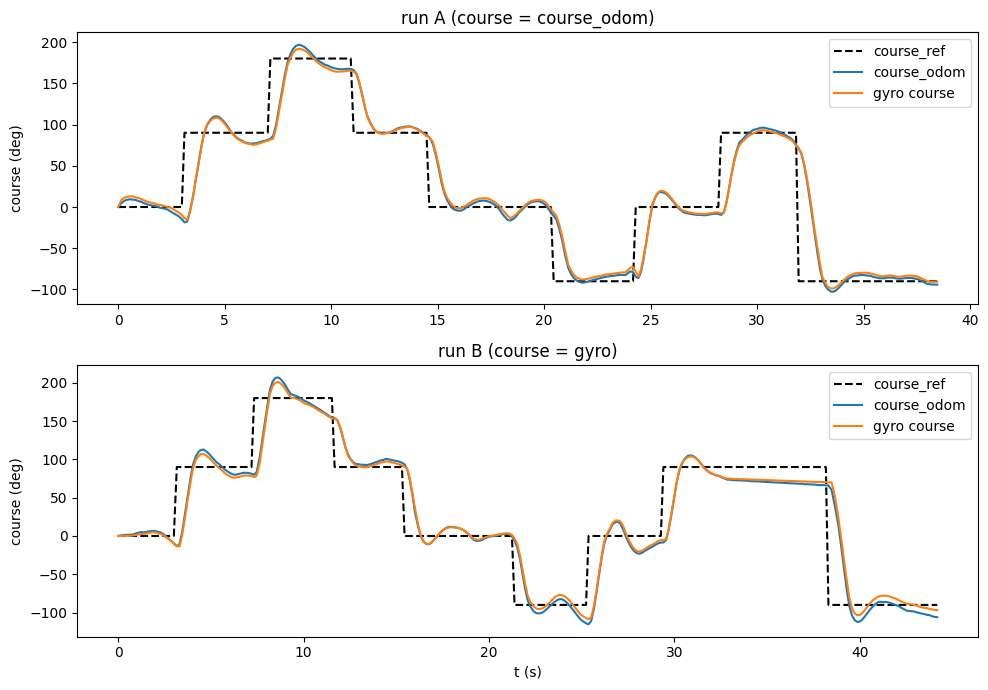

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
for a, run, name in [(ax[0], runA, 'run A (course = course_odom)'), (ax[1], runB, 'run B (course = gyro)')]:
    a.plot(run.t, course_ref[run.seg - 1], 'k--', label='course_ref')
    a.plot(run.t, np.degrees(run.c_odom), label='course_odom')
    a.plot(run.t, np.degrees(run.c_gyro), label='gyro course')
    a.set_title(name); a.set_ylabel('course (deg)'); a.legend()
ax[1].set_xlabel('t (s)')
plt.tight_layout(); plt.show()

## 5. Path per segment

In [14]:
def segment_path(run):
    # path driven on each segment, cm
    end = run.groupby('seg').path.last()       # path at the end of each segment
    return np.diff(end, prepend=0)

pA, pB = segment_path(runA), segment_path(runB)
d_pA, d_pB = pA - path_ref, pB - path_ref

for k in range(10):
    print(f'segment {k + 1}: path_ref {path_ref[k]:4.0f} | A {pA[k]:5.1f} ({d_pA[k]:+.1f}) | '
          f'B {pB[k]:5.1f} ({d_pB[k]:+.1f}) cm')
for name, p in [('A', pA), ('B', pB)]:
    print(f'run {name}: total {p.sum():.1f} cm vs {path_ref.sum():.0f} cm ({(p.sum() / path_ref.sum() - 1) * 100:+.1f} %)')

segment 1: path_ref   50 | A  47.4 (-2.6) | B  46.4 (-3.6) cm
segment 2: path_ref   50 | A  49.0 (-1.0) | B  48.9 (-1.1) cm
segment 3: path_ref   50 | A  48.9 (-1.1) | B  48.9 (-1.1) cm
segment 4: path_ref   50 | A  48.9 (-1.1) | B  48.5 (-1.5) cm
segment 5: path_ref   50 | A  50.5 (+0.5) | B  48.8 (-1.2) cm
segment 6: path_ref   30 | A  29.9 (-0.1) | B  30.3 (+0.3) cm
segment 7: path_ref   50 | A  48.8 (-1.2) | B  50.1 (+0.1) cm
segment 8: path_ref   50 | A  48.9 (-1.1) | B  49.0 (-1.0) cm
segment 9: path_ref   50 | A  48.0 (-2.0) | B  47.8 (-2.2) cm
segment 10: path_ref  100 | A  97.6 (-2.4) | B  92.8 (-7.2) cm
run A: total 517.9 cm vs 530 cm (-2.3 %)
run B: total 511.5 cm vs 530 cm (-3.5 %)


In [15]:
# the path on a segment is the length of the robot's curve. Split it into the straight line between
# the segment's start and end points (corner cutting) and the extra length of the curve (arcs).
for name, run in [('A', runA), ('B', runB)]:
    end = run.groupby('seg')[['x', 'y', 'path']].last()          # logged end point of each segment
    chord = np.hypot(np.diff(np.r_[0, end.x]), np.diff(np.r_[0, end.y]))   # straight line, cm
    curve = np.diff(np.r_[0, end.path])                           # path on the segment, cm
    dist_end = np.hypot(end.x - X_ref[1:], end.y - Y_ref[1:])     # distance to the waypoint when the segment ended
    turning = (run.seg == 10) & (run.ca.abs() > 45)               # the 180° turn in place at the start of segment 10
    print(f'run {name}: corner cutting {np.sum(chord - path_ref):+.1f} cm, arcs {np.sum(curve - chord):+.1f} cm '
          f'(segment 10: {chord[9] - path_ref[9]:+.1f} / {curve[9] - chord[9]:+.1f} cm); '
          f'segments ended {dist_end.min():.1f}-{dist_end.max():.1f} cm from the waypoint; '
          f'moved {run.path.diff()[turning].sum():+.1f} cm during the 180° turn')

run A: corner cutting -32.8 cm, arcs +20.7 cm (segment 10: -6.5 / +4.1 cm); segments ended 3.3-3.9 cm from the waypoint; moved +2.3 cm during the 180° turn
run B: corner cutting -34.6 cm, arcs +16.1 cm (segment 10: -6.3 / -0.9 cm); segments ended 2.9-4.0 cm from the waypoint; moved -0.9 cm during the 180° turn


## 6. Error growth

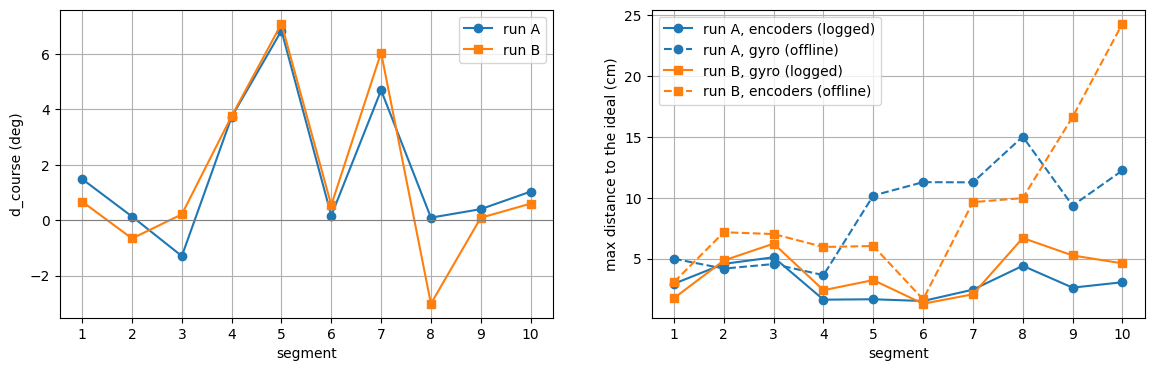

max distance to the ideal per segment (cm)
            1    2    3    4     5     6     7     8     9     10
A logged   2.9  4.6  5.1  1.6   1.7   1.5   2.4   4.4   2.6   3.1
A offline  5.0  4.2  4.6  3.6  10.2  11.3  11.3  15.0   9.4  12.2
B logged   1.8  4.8  6.2  2.4   3.2   1.3   2.1   6.7   5.3   4.6
B offline  3.1  7.2  7.0  6.0   6.0   1.7   9.6  10.0  16.6  24.3


In [16]:
ideal = np.vstack([np.linspace(wp[k], wp[k + 1], 101) for k in range(10)])

def dist_to_ideal(x, y):
    # distance from each point to the nearest point of the ideal trajectory, cm
    return np.array([np.min(np.hypot(ideal[:, 0] - px, ideal[:, 1] - py)) for px, py in zip(x, y)])

def max_per_segment(run, m):
    # largest distance to the ideal on each segment, for the path with course m ('odom' or 'gyro')
    d = pd.Series(dist_to_ideal(run['x_' + m], run['y_' + m]))
    return d.groupby(run.seg).max().values

eA_own, eA_other = max_per_segment(runA, 'odom'), max_per_segment(runA, 'gyro')
eB_own, eB_other = max_per_segment(runB, 'gyro'), max_per_segment(runB, 'odom')

segs = np.arange(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(segs, d_cA, 'o-', label='run A')
ax[0].plot(segs, d_cB, 's-', label='run B')
ax[0].axhline(0, c='gray', lw=0.8); ax[0].set_ylabel('d_course (deg)')
ax[1].plot(segs, eA_own, 'o-', c='C0', label='run A, encoders (logged)')
ax[1].plot(segs, eA_other, 'o--', c='C0', label='run A, gyro (offline)')
ax[1].plot(segs, eB_own, 's-', c='C1', label='run B, gyro (logged)')
ax[1].plot(segs, eB_other, 's--', c='C1', label='run B, encoders (offline)')
ax[1].set_ylabel('max distance to the ideal (cm)')
for a in ax:
    a.set_xlabel('segment'); a.set_xticks(segs); a.grid(True); a.legend()
plt.show()

print('max distance to the ideal per segment (cm)')
print(pd.DataFrame({'A logged': eA_own, 'A offline': eA_other, 'B logged': eB_own, 'B offline': eB_other},
                   index=segs).round(1).T.to_string())

In [17]:
# final position and course error, relative to the last waypoint (130, 0) and the last course_ref (−90 deg)
for name, run, m, how in [('A', runA, 'odom', 'logged'), ('A', runA, 'gyro', 'offline'),
                          ('B', runB, 'gyro', 'logged'), ('B', runB, 'odom', 'offline')]:
    x, y = run['x_' + m].iloc[-1], run['y_' + m].iloc[-1]
    c = np.degrees(run['c_' + m].iloc[-1])
    print(f'run {name}, {m} course ({how}): end ({x:.1f}, {y:.1f}) cm, '
          f'{np.hypot(x - X_ref[-1], y - Y_ref[-1]):.1f} cm from the last waypoint, '
          f'course error {c - course_ref[-1]:+.1f} deg')

run A, odom course (logged): end (130.9, 3.5) cm, 3.6 cm from the last waypoint, course error -4.2 deg
run A, gyro course (offline): end (142.2, 14.9) cm, 19.3 cm from the last waypoint, course error -0.6 deg
run B, gyro course (logged): end (130.7, 2.8) cm, 2.9 cm from the last waypoint, course error -6.8 deg
run B, odom course (offline): end (105.7, -1.3) cm, 24.3 cm from the last waypoint, course error -16.1 deg


## 7. Comparison table

In [18]:
table = pd.DataFrame({'course_ref': course_ref, 'course A': cA, 'course B': cB,
                      'd_course A': d_cA, 'd_course B': d_cB,
                      'path_ref': path_ref, 'path A': pA, 'path B': pB,
                      'd_path A': d_pA, 'd_path B': d_pB}, index=segs)
table.loc['summary'] = [np.nan, np.nan, np.nan, np.abs(d_cA).mean(), np.abs(d_cB).mean(),
                        path_ref.sum(), pA.sum(), pB.sum(), d_pA.sum(), d_pB.sum()]
print(table.round(1).to_string(na_rep=''))

         course_ref  course A  course B  d_course A  d_course B  path_ref  path A  path B  d_path A  d_path B
1               0.0       1.5       0.7         1.5         0.7      50.0    47.4    46.4      -2.6      -3.6
2              90.0      90.1      89.3         0.1        -0.7      50.0    49.0    48.9      -1.0      -1.1
3             180.0     178.7     180.2        -1.3         0.2      50.0    48.9    48.9      -1.1      -1.1
4              90.0      93.7      93.8         3.7         3.8      50.0    48.9    48.5      -1.1      -1.5
5               0.0       6.8       7.1         6.8         7.1      50.0    50.5    48.8       0.5      -1.2
6               0.0       0.2       0.5         0.2         0.5      30.0    29.9    30.3      -0.1       0.3
7             -90.0     -85.3     -83.9         4.7         6.1      50.0    48.8    50.1      -1.2       0.1
8               0.0       0.1      -3.0         0.1        -3.0      50.0    48.9    49.0      -1.1      -1.0
9         

| Seg. | `course_ref` (°) | `course` A (°) | `course` B (°) | `d_course` A / B (°) | `path_ref` (cm) | `path` A (cm) | `path` B (cm) | `d_path` A / B (cm) |
|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | 1.5 | 0.7 | +1.5 / +0.7 | 50 | 47.4 | 46.4 | -2.6 / -3.6 |
| 2 | 90.0 | 90.1 | 89.3 | +0.1 / -0.7 | 50 | 49.0 | 48.9 | -1.0 / -1.1 |
| 3 | 180.0 | 178.7 | 180.2 | -1.3 / +0.2 | 50 | 48.9 | 48.9 | -1.1 / -1.1 |
| 4 | 90.0 | 93.7 | 93.8 | +3.7 / +3.8 | 50 | 48.9 | 48.5 | -1.1 / -1.5 |
| 5 | 0.0 | 6.8 | 7.1 | +6.8 / +7.1 | 50 | 50.5 | 48.8 | +0.5 / -1.2 |
| 6 | 0.0 | 0.2 | 0.5 | +0.2 / +0.5 | 30 | 29.9 | 30.3 | -0.1 / +0.3 |
| 7 | -90.0 | -85.3 | -83.9 | +4.7 / +6.1 | 50 | 48.8 | 50.1 | -1.2 / +0.1 |
| 8 | 0.0 | 0.1 | -3.0 | +0.1 / -3.0 | 50 | 48.9 | 49.0 | -1.1 / -1.0 |
| 9 | 90.0 | 90.4 | 90.1 | +0.4 / +0.1 | 50 | 48.0 | 47.8 | -2.0 / -2.2 |
| 10 | -90.0 | -89.0 | -89.4 | +1.0 / +0.6 | 100 | 97.6 | 92.8 | -2.4 / -7.2 |
| **Summary** | | | | mean abs: 2.0 / 2.3 | 530 | 517.9 | 511.5 | total -12.1 / -18.5 (-2.3 % / -3.5 %) |

Final position error relative to the last waypoint, logged: A 3.6 cm, B 2.9 cm. Final course error relative to the last `course_ref`, logged: A -4.2°, B -6.8°. Offline, with the other course (§6): A 19.3 cm and -0.6°; B 24.3 cm and -16.1°.

## 8. Analysis

1. Course and path. In the logs both runs look good. The mean course error is 2.0° (A) and 2.3° (B), the path is 2.3 % and 3.5 % short, and both runs end within 4 cm of the last waypoint. But the logs are the robot's own estimate, and the controller steers that estimate to the waypoints. So these numbers show how well the controller works, not how good the localization is. The path errors are similar because both runs measure the path the same way, with the encoders; only the course is different. The difference shows when each run is recomputed with the other sensor: the two courses drift apart by up to 6° (A) and 13° (B), and the recomputed runs end 19 cm and 24 cm from the last waypoint. Which run was really closer depends on which sensor was right. The evidence below points to the gyro, so probably run B, but I did not measure the real end points. The controller also overshoots each turn by up to 30° and arcs back, so the mean course of a segment hides large swings.

2. Error sources. In 13–14 of the 16 turns, the encoders count more turning than the gyro, by up to about 8° in one segment. A wrong B explains only a small part: the best-fit wheel base is 19.5–19.7 cm instead of 19.4 cm, about 1° per 90° turn. The rest changes from turn to turn, which points to wheel slip. The clearest example is the slow pivot near waypoint 9 in run B: the encoders counted 9.1° of turning, the gyro only 5.5–6.4°. So slip dominated the encoder course (run A). In the gyro course (run B), the bias measured at the start was removed, the scale factor was corrected, and the gyro never saturated (185°/s at most, against a range of 287°/s). Its main weakness was sampling: it was read only about 7 times a second, so each segment is uncertain by up to about 3°. The gyro is probably the better course, but with this slow loop I cannot fully separate slip from the sampling error.

3. Combining them. Each sensor is good where the other is weak. The gyro measures turns without slip but drifts slowly (about 2° per minute in Lab 9). The encoders don't drift when driving straight but pick up an error in every turn. A complementary filter uses both: course = 0.01 · course_odom + 0.99 · (course + gyro_inc). The gyro follows fast changes, and the encoders slowly pull the course back. How slowly depends on the loop time. With 0.01, it takes about 13.5 s with this loop (≈ 135 ms per step) but only 1 s with a 10-ms loop, so the weight should be chosen in seconds. I would also use the measured B, turn more slowly to reduce slip and overshoot, and make the loop faster.